# Enriquecimento das avaliações

Monta a tabela base do sistema: uma linha por avaliação com comentário, acrescida das informações das demais tabelas da Olist. Essas informações servem de filtro e de contexto para as ferramentas de contagem e para a busca de comentários.

| Tabela | Entra como |
|---|---|
| pedidos | data da compra, data de despacho à transportadora, data prevista e data real de entrega, status, atraso em dias e faixa de atraso |
| itens e produtos | categorias dos produtos, número de itens, valor dos produtos e do frete, prazo limite de despacho, peso e volume dos produtos |
| vendedores | código e estado do vendedor |
| pagamentos | forma de pagamento principal, parcelas, valor pago |
| clientes | estado e cidade do cliente, código único do cliente e número de pedidos feitos por ele |
| geolocalização | localização aproximada do cliente e distância em quilômetros entre vendedor e cliente |

Regras de junção (diário de decisões, D-016 a D-018):

- uma linha por avaliação, e não por linha da tabela original;
- tabelas com várias linhas por pedido (itens, pagamentos) entram resumidas por pedido;
- pedido com produtos de categorias diferentes recebe todas as categorias;
- avaliação ligada a mais de um pedido recebe as categorias de todos e o maior atraso;
- pedido sem data de entrega recebe a faixa "não entregue".

📌 Saída: `data/processed/avaliacoes_enriquecidas.parquet`.

## Carregamento

As nove tabelas da base, com o número de linhas e as colunas de cada uma.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DADOS = RAIZ / "data" / "raw"
SAIDA = RAIZ / "data" / "processed"

ARQUIVOS = {
    "avaliacoes": "olist_order_reviews_dataset.csv",
    "pedidos": "olist_orders_dataset.csv",
    "itens": "olist_order_items_dataset.csv",
    "produtos": "olist_products_dataset.csv",
    "pagamentos": "olist_order_payments_dataset.csv",
    "clientes": "olist_customers_dataset.csv",
    "vendedores": "olist_sellers_dataset.csv",
    "geolocalizacao": "olist_geolocation_dataset.csv",
}
tabelas = {nome: pd.read_csv(DADOS / arquivo) for nome, arquivo in ARQUIVOS.items()}

display(pd.DataFrame({
    "linhas": {nome: len(t) for nome, t in tabelas.items()},
    "colunas": {nome: t.shape[1] for nome, t in tabelas.items()},
}))
for nome, t in tabelas.items():
    print(f"{nome}: {', '.join(t.columns)}")

,linhas,colunas
avaliacoes,99224,7
pedidos,99441,8
itens,112650,7
produtos,32951,9
pagamentos,103886,5
clientes,99441,5
vendedores,3095,4
geolocalizacao,1000163,5


avaliacoes: review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp
pedidos: order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date
itens: order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value
produtos: product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm
pagamentos: order_id, payment_sequential, payment_type, payment_installments, payment_value
clientes: customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state
vendedores: seller_id, seller_zip_code_prefix, seller_city, seller_state
geolocalizacao: geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state


## Relações entre as tabelas

As tabelas se ligam pelos códigos abaixo. O pedido é o centro: todas as junções passam por ele.

```
avaliações ──order_id──► pedidos ──customer_id──► clientes ──CEP──► geolocalização
                            │
                            ├──order_id──► pagamentos
                            │
                            └──order_id──► itens ──product_id──► produtos
                                             │
                                             └──seller_id──► vendedores ──CEP──► geolocalização
```

Antes de juntar, a seção confere duas coisas em cada ligação:

- **Cardinalidade:** quantas linhas de uma tabela correspondem a cada código da outra. Uma ligação que se supõe de um para um e é, na verdade, de um para vários duplica linhas na junção sem aviso.
- **Códigos sem par:** códigos de uma tabela que não existem na outra, e que ficariam sem informação depois da junção.

**O que se espera.**

| Ligação | Esperado | Consequência para a junção |
|---|---|---|
| avaliação e pedido | quase sempre um para um, com poucos casos de vários para vários (etapa de análise exploratória) | resolvido por D-016 e D-018 |
| pedido e cliente (`customer_id`) | um para um | junção direta |
| cliente único e pedidos | um cliente único pode ter vários pedidos | permite contar recompras |
| pedido e itens | um para vários | resumir por pedido antes de juntar |
| pedido e pagamentos | um para vários (por exemplo, cartão e voucher no mesmo pedido) | resumir por pedido antes de juntar |
| item e produto, item e vendedor | cada produto e cada vendedor aparecem uma única vez nas suas tabelas | junção direta |
| CEP e geolocalização | um para vários: vários pontos por prefixo de CEP | resumir por CEP antes de juntar |

In [2]:
av, pe, it, pr, pg, cl, ve, geo = (
    tabelas[nome] for nome in
    ["avaliacoes", "pedidos", "itens", "produtos", "pagamentos", "clientes", "vendedores", "geolocalizacao"]
)


def resumir(contagem):
    return {
        "códigos": len(contagem),
        "mínimo": contagem.min(),
        "máximo": contagem.max(),
        "% com mais de 1": round((contagem > 1).mean() * 100, 2),
    }


cardinalidade = pd.DataFrame({
    "avaliações por pedido": resumir(av.groupby("order_id").size()),
    "pedidos por avaliação": resumir(av.groupby("review_id")["order_id"].nunique()),
    "pedidos por customer_id": resumir(pe.groupby("customer_id").size()),
    "pedidos por cliente único": resumir(pe.merge(cl, on="customer_id").groupby("customer_unique_id").size()),
    "itens por pedido": resumir(it.groupby("order_id").size()),
    "produtos distintos por pedido": resumir(it.groupby("order_id")["product_id"].nunique()),
    "vendedores distintos por pedido": resumir(it.groupby("order_id")["seller_id"].nunique()),
    "pagamentos por pedido": resumir(pg.groupby("order_id").size()),
    "linhas por produto (tabela de produtos)": resumir(pr.groupby("product_id").size()),
    "linhas por vendedor (tabela de vendedores)": resumir(ve.groupby("seller_id").size()),
    "pontos por CEP (geolocalização)": resumir(geo.groupby("geolocation_zip_code_prefix").size()),
}).T
display(cardinalidade)

sem_par = pd.Series({
    "avaliações sem pedido": (~av["order_id"].isin(pe["order_id"])).sum(),
    "pedidos sem item": (~pe["order_id"].isin(it["order_id"])).sum(),
    "pedidos sem pagamento": (~pe["order_id"].isin(pg["order_id"])).sum(),
    "pedidos sem cliente": (~pe["customer_id"].isin(cl["customer_id"])).sum(),
    "itens sem produto": (~it["product_id"].isin(pr["product_id"])).sum(),
    "itens sem vendedor": (~it["seller_id"].isin(ve["seller_id"])).sum(),
    "produtos sem categoria": pr["product_category_name"].isna().sum(),
    "CEPs de cliente sem geolocalização": (~cl["customer_zip_code_prefix"].isin(geo["geolocation_zip_code_prefix"])).sum(),
    "CEPs de vendedor sem geolocalização": (~ve["seller_zip_code_prefix"].isin(geo["geolocation_zip_code_prefix"])).sum(),
})
display(sem_par.to_frame("quantidade"))

,códigos,mínimo,máximo,% com mais de 1
avaliações por pedido,98673.0,1.0,3.0,0.55
pedidos por avaliação,98410.0,1.0,3.0,0.80
pedidos por customer_id,99441.0,1.0,1.0,0.00
pedidos por cliente único,96096.0,1.0,17.0,3.12
itens por pedido,98666.0,1.0,21.0,9.94
produtos distintos por pedido,98666.0,1.0,8.0,3.28
vendedores distintos por pedido,98666.0,1.0,5.0,1.30
pagamentos por pedido,99440.0,1.0,29.0,2.98
linhas por produto (tabela de produtos),32951.0,1.0,1.0,0.00
linhas por vendedor (tabela de vendedores),3095.0,1.0,1.0,0.00


,quantidade
avaliações sem pedido,0
pedidos sem item,775
pedidos sem pagamento,1
pedidos sem cliente,0
itens sem produto,0
itens sem vendedor,0
produtos sem categoria,610
CEPs de cliente sem geolocalização,278
CEPs de vendedor sem geolocalização,7


**Leitura.** As ligações se comportam como esperado. Cada pedido tem exatamente um `customer_id`, e produtos e vendedores aparecem uma única vez nas suas tabelas, o que permite junção direta nesses pontos. O `customer_id` muda a cada pedido: para identificar a pessoa, só o código único do cliente, e apenas 3,1% dos clientes compraram mais de uma vez.

Itens, pagamentos e pontos de geolocalização são de um para vários e precisam ser resumidos antes da junção. Embora 9,9% dos pedidos tenham mais de um item, só 3,3% têm produtos diferentes: na maioria dos casos é o mesmo produto em quantidade. Na geolocalização, 94,5% dos prefixos de CEP têm mais de um ponto, com até 1.146 pontos no mesmo prefixo.

Ficam sem par 775 pedidos sem item, 610 produtos sem categoria, 278 CEPs de cliente e 7 de vendedor sem localização, e 1 pedido sem pagamento.

**Regras de resumo** (D-019):

| Situação | Regra |
|---|---|
| pedido com vários vendedores (1,3%) | lista dos vendedores; distância e atraso no despacho pelo pior caso, como em D-018 |
| pedido com vários pagamentos (3,0%) | forma principal é a de maior valor; valor pago é a soma; parcelas é o máximo |
| prefixo de CEP com vários pontos | mediana da latitude e da longitude, que resiste a pontos errados |
| pedido sem item ou produto sem categoria | categoria "sem informação" |
| CEP sem localização | distância vazia |

## 1. Seleção das avaliações

Ponto de partida da tabela base: as avaliações com comentário escrito que tenha conteúdo.

1. Fica de fora a avaliação sem comentário. Ela continua disponível nas contagens de total.
2. Fica de fora o comentário sem nenhuma letra ou número (apenas pontuação ou emoji), que não carrega conteúdo.
3. A avaliação replicada em mais de um pedido vira uma única linha, com a lista dos pedidos a que pertence (D-016). A célula confere que o texto é o mesmo em todas as cópias.

In [3]:
avaliacoes = av.copy()
avaliacoes["texto"] = avaliacoes["review_comment_message"].fillna("").str.replace(r"\s+", " ", regex=True).str.strip()
avaliacoes["tem_conteudo"] = avaliacoes["texto"].str.contains(r"[0-9A-Za-zÀ-ÿ]", regex=True)

com_texto = avaliacoes[avaliacoes["texto"].ne("")]
com_conteudo = com_texto[com_texto["tem_conteudo"]]

textos_por_avaliacao = com_conteudo.groupby("review_id")["texto"].nunique()
print(f"avaliações replicadas com textos diferentes entre as cópias: {(textos_por_avaliacao > 1).sum()}")

base = (
    com_conteudo.sort_values("review_id")
    .drop_duplicates("review_id")
    .set_index("review_id")
    [["review_score", "review_comment_title", "texto", "review_creation_date", "review_answer_timestamp"]]
)
base["pedidos"] = com_conteudo.groupby("review_id")["order_id"].agg(lambda codigos: sorted(set(codigos)))
base["n_pedidos"] = base["pedidos"].str.len()

display(pd.Series({
    "linhas da tabela de avaliações": len(avaliacoes),
    "com comentário escrito": len(com_texto),
    "com letra ou número": len(com_conteudo),
    "avaliações distintas (tabela base)": len(base),
}).to_frame("linhas"))
display(base["n_pedidos"].value_counts().sort_index().to_frame("avaliações"))

print("Comentários removidos por não terem letra nem número:")
display(com_texto.loc[~com_texto["tem_conteudo"], "texto"].value_counts().head(10).to_frame("vezes"))

avaliações replicadas com textos diferentes entre as cópias: 0


,linhas
linhas da tabela de avaliações,99224
com comentário escrito,40950
com letra ou número,40827
avaliações distintas (tabela base),40518


,avaliações
n_pedidos,
1,40219
2,289
3,10


Comentários removidos por não terem letra nem número:


,vezes
texto,
.,52
...,11
..,8
.....,3
👍🏻,3
?,3
-,3
....,3
👍,2


**Leitura.** Dos 40.950 comentários escritos, 123 não têm letra nem número (".", "...", emojis) e saem da base. As avaliações replicadas em mais de um pedido têm o mesmo texto em todas as cópias, o que confirma a premissa de D-016. A tabela base parte de **40.518 avaliações distintas**: 40.219 ligadas a um pedido, 289 a dois e 10 a três.

## 2. Pedidos: datas, atraso e despacho

Cada pedido recebe as medidas de prazo que alimentam os filtros de entrega:

| Campo | Cálculo |
|---|---|
| prazo previsto | data prevista de entrega menos data da compra |
| prazo real | data de entrega ao cliente menos data da compra |
| atraso | data de entrega ao cliente menos data prevista, em dias (negativo quando chegou antes) |
| atraso no despacho | data de entrega à transportadora menos o prazo limite de despacho do vendedor |
| tempo de transporte | data de entrega ao cliente menos data de entrega à transportadora |
| faixa de atraso | dentro do prazo, atraso de 1 a 7 dias, atraso acima de 7 dias, não entregue |

O atraso no despacho e o tempo de transporte separam a parte do atraso que cabe ao vendedor da parte que cabe à logística. A faixa "dentro do prazo" reúne entregas antecipadas e no dia previsto; o atraso em dias continua disponível para recortes mais finos.

**O que se espera.** A maior parte dos pedidos chega dentro do prazo, porque a data prevista costuma ter folga. Os atrasados são poucos, e os não entregues menos ainda. Entre os atrasados, a maior parte do atraso vem do transporte, e não do despacho.

A célula também procura datas inconsistentes, como entrega ao cliente antes do despacho.

In [4]:
DATAS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
pedidos = pe.copy()
for coluna in DATAS:
    pedidos[coluna] = pd.to_datetime(pedidos[coluna])

limite_despacho = pd.to_datetime(it["shipping_limit_date"]).groupby(it["order_id"]).min()
pedidos["limite_despacho"] = pedidos["order_id"].map(limite_despacho)


def em_dias(intervalo):
    return (intervalo.dt.total_seconds() / 86400).round(1)


pedidos["prazo_previsto_dias"] = em_dias(pedidos["order_estimated_delivery_date"] - pedidos["order_purchase_timestamp"])
pedidos["prazo_real_dias"] = em_dias(pedidos["order_delivered_customer_date"] - pedidos["order_purchase_timestamp"])
pedidos["atraso_dias"] = (
    pedidos["order_delivered_customer_date"].dt.normalize() - pedidos["order_estimated_delivery_date"].dt.normalize()
).dt.days
pedidos["atraso_despacho_dias"] = em_dias(pedidos["order_delivered_carrier_date"] - pedidos["limite_despacho"])
pedidos["transporte_dias"] = em_dias(pedidos["order_delivered_customer_date"] - pedidos["order_delivered_carrier_date"])

FAIXAS = ["dentro do prazo", "atraso de 1 a 7 dias", "atraso acima de 7 dias", "não entregue"]
pedidos["faixa_atraso"] = np.select(
    [
        pedidos["order_delivered_customer_date"].isna(),
        pedidos["atraso_dias"] <= 0,
        pedidos["atraso_dias"] <= 7,
    ],
    ["não entregue", "dentro do prazo", "atraso de 1 a 7 dias"],
    default="atraso acima de 7 dias",
)

display(pedidos["order_status"].value_counts().to_frame("pedidos"))

faixas = pedidos["faixa_atraso"].value_counts().reindex(FAIXAS).to_frame("pedidos")
faixas["%"] = (faixas["pedidos"] / faixas["pedidos"].sum() * 100).round(1)
display(faixas)

medidas = ["prazo_previsto_dias", "prazo_real_dias", "atraso_dias", "atraso_despacho_dias", "transporte_dias"]
display(pedidos[medidas].describe(percentiles=[0.1, 0.5, 0.9]).round(1).T)

atrasados = pedidos[pedidos["atraso_dias"] > 0]
no_prazo = pedidos[pedidos["atraso_dias"] <= 0]
print(f"pedidos entregues com atraso: {len(atrasados):,}".replace(",", "."))
print(f"  com despacho do vendedor depois do prazo limite: {(atrasados['atraso_despacho_dias'] > 0).mean():.1%}")
print(f"  (entre os entregues dentro do prazo: {(no_prazo['atraso_despacho_dias'] > 0).mean():.1%})")
print(f"  tempo de transporte mediano: {atrasados['transporte_dias'].median():.1f} dias "
      f"(contra {no_prazo['transporte_dias'].median():.1f} nos entregues dentro do prazo)")

display(pd.Series({
    "entrega ao cliente antes do despacho": (pedidos["order_delivered_customer_date"] < pedidos["order_delivered_carrier_date"]).sum(),
    "despacho antes da compra": (pedidos["order_delivered_carrier_date"] < pedidos["order_purchase_timestamp"]).sum(),
    "status entregue sem data de entrega": ((pedidos["order_status"] == "delivered") & pedidos["order_delivered_customer_date"].isna()).sum(),
    "data de entrega com outro status": ((pedidos["order_status"] != "delivered") & pedidos["order_delivered_customer_date"].notna()).sum(),
}).to_frame("pedidos"))

,pedidos
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


,pedidos,%
faixa_atraso,,
dentro do prazo,89941,90.4
atraso de 1 a 7 dias,3672,3.7
atraso acima de 7 dias,2863,2.9
não entregue,2965,3.0


,count,mean,std,min,10%,50%,90%,max
prazo_previsto_dias,99441.0,23.8,8.8,1.6,13.1,23.2,34.3,155.1
prazo_real_dias,96476.0,12.6,9.5,0.5,4.2,10.2,23.1,209.6
atraso_dias,96476.0,-11.9,10.2,-147.0,-22.0,-12.0,-2.0,188.0
atraso_despacho_dias,97657.0,-3.3,6.0,-1054.2,-6.4,-3.2,-0.1,116.8
transporte_dias,96475.0,9.3,8.8,-16.1,1.9,7.1,18.9,205.2


pedidos entregues com atraso: 6.535
  com despacho do vendedor depois do prazo limite: 27.3%
  (entre os entregues dentro do prazo: 7.3%)
  tempo de transporte mediano: 26.2 dias (contra 6.9 nos entregues dentro do prazo)


,pedidos
entrega ao cliente antes do despacho,23
despacho antes da compra,166
status entregue sem data de entrega,8
data de entrega com outro status,6


**Leitura.** A previsão se confirmou: 90,4% dos pedidos chegaram dentro do prazo, 3,7% com atraso de 1 a 7 dias, 2,9% com atraso acima de 7 dias e 3,0% não foram entregues. A data prevista tem muita folga: o prazo prometido tem mediana de 23,2 dias, e o pedido chega em 10,2. O pedido típico chega 12 dias antes do prometido, o que ajuda a explicar a frequência do elogio "chegou antes do prazo".

Entre os 6.535 pedidos entregues com atraso, 27,3% tiveram despacho do vendedor depois do prazo limite, contra 7,3% entre os entregues dentro do prazo. O tempo de transporte, porém, é o que mais diferencia os dois grupos: mediana de 26,2 dias nos atrasados contra 6,9 nos demais. Os dois fatores contribuem, e o transporte pesa mais.

A faixa "não entregue" reúne pedidos cancelados, indisponíveis e os que ainda estavam em trânsito ou em processamento quando a base foi extraída. Para quem avaliou, o significado é o mesmo: o produto não tinha chegado quando a pesquisa foi enviada.

⚠️ **Datas inconsistentes.** 166 pedidos têm despacho registrado antes da compra e 23 têm entrega ao cliente antes do despacho, o que produz valores impossíveis (atraso no despacho de até 1.054 dias negativos). Nesses 189 pedidos (0,2%), o atraso no despacho e o tempo de transporte ficam vazios. Há ainda 10 pedidos com prazo limite de despacho mais de 60 dias depois da compra (um deles em 2020), quando a mediana é de 6 dias; neles, o atraso no despacho fica vazio. A faixa de atraso não é afetada, porque depende apenas da data prevista e da data de entrega ao cliente.

In [5]:
prazo_limite_dias = (pedidos["limite_despacho"] - pedidos["order_purchase_timestamp"]).dt.total_seconds() / 86400

inconsistente = (
    (pedidos["order_delivered_carrier_date"] < pedidos["order_purchase_timestamp"])
    | (pedidos["order_delivered_customer_date"] < pedidos["order_delivered_carrier_date"])
)
limite_implausivel = prazo_limite_dias > 60

pedidos.loc[inconsistente, ["atraso_despacho_dias", "transporte_dias"]] = np.nan
pedidos.loc[limite_implausivel, "atraso_despacho_dias"] = np.nan

print(f"pedidos com datas em ordem impossível: {inconsistente.sum()}")
print(f"pedidos com prazo limite de despacho mais de 60 dias depois da compra: {limite_implausivel.sum()}")
print(f"prazo limite de despacho, mediana: {prazo_limite_dias.median():.1f} dias")
display(pedidos[["atraso_despacho_dias", "transporte_dias"]].describe().round(1).T)

pedidos com datas em ordem impossível: 189
pedidos com prazo limite de despacho mais de 60 dias depois da compra: 10
prazo limite de despacho, mediana: 6.0 dias


,count,mean,std,min,25%,50%,75%,max
atraso_despacho_dias,97462.0,-3.3,3.7,-48.3,-5.2,-3.2,-1.6,116.8
transporte_dias,96287.0,9.3,8.7,0.0,4.1,7.1,12.0,205.2


## 3. Itens, produtos e vendedores

Cada pedido recebe o resumo dos seus itens:

| Campo | Cálculo |
|---|---|
| categorias | lista das categorias dos produtos do pedido, sem repetição (D-018) |
| número de itens | quantidade de linhas do pedido na tabela de itens |
| valor dos produtos e do frete | soma dos itens |
| peso e volume | soma dos itens, a partir do peso e das dimensões de cada produto |
| vendedores | lista dos vendedores do pedido, com o estado e o CEP de cada um |

As categorias vêm em português, com o sublinhado trocado por espaço ("cama_mesa_banho" vira "cama mesa banho"). Produto sem categoria e pedido sem item recebem "sem informação" (D-019).

**O que se espera.** Poucos pedidos com mais de uma categoria (3,3% têm produtos diferentes, pela verificação das ligações). As categorias de casa e decoração, beleza e esporte entre as mais vendidas.

In [6]:
itens = (
    it.merge(
        pr[["product_id", "product_category_name", "product_weight_g",
            "product_length_cm", "product_height_cm", "product_width_cm"]],
        on="product_id", how="left",
    )
    .merge(ve[["seller_id", "seller_state", "seller_zip_code_prefix"]], on="seller_id", how="left")
)
itens["categoria"] = itens["product_category_name"].fillna("sem informação").str.replace("_", " ")
itens["volume_cm3"] = itens["product_length_cm"] * itens["product_height_cm"] * itens["product_width_cm"]


def lista(valores):
    return sorted(set(valores.dropna()))


def soma(valores):
    return valores.sum(min_count=1)


itens_pedido = itens.groupby("order_id").agg(
    categorias=("categoria", lista),
    n_itens=("order_item_id", "size"),
    valor_produtos=("price", "sum"),
    valor_frete=("freight_value", "sum"),
    peso_total_g=("product_weight_g", soma),
    volume_total_cm3=("volume_cm3", soma),
    vendedores=("seller_id", lista),
    estados_vendedor=("seller_state", lista),
    ceps_vendedor=("seller_zip_code_prefix", lista),
)
itens_pedido["n_categorias"] = itens_pedido["categorias"].str.len()
itens_pedido["n_vendedores"] = itens_pedido["vendedores"].str.len()

print(f"pedidos com itens: {len(itens_pedido):,}".replace(",", "."))
display(itens_pedido["n_categorias"].value_counts().sort_index().to_frame("pedidos"))
display(itens_pedido[["n_itens", "valor_produtos", "valor_frete", "peso_total_g", "volume_total_cm3"]]
        .describe(percentiles=[0.1, 0.5, 0.9]).round(1).T)

categorias = itens_pedido["categorias"].explode().value_counts()
print(f"categorias distintas: {len(categorias)}")
display(categorias.head(15).to_frame("pedidos"))

pedidos com itens: 98.666


,pedidos
n_categorias,
1,97880
2,768
3,18


,count,mean,std,min,10%,50%,90%,max
n_itens,98666.0,1.1,0.5,1.0,1.0,1.0,1.0,21.0
valor_produtos,98666.0,137.8,210.6,0.8,25.0,86.9,269.9,13440.0
valor_frete,98666.0,22.8,21.7,0.0,9.3,17.2,39.5,1795.0
peso_total_g,98650.0,2390.4,4773.5,0.0,175.0,750.0,6550.0,184400.0
volume_total_cm3,98650.0,17404.3,30403.8,168.0,1408.0,7260.0,43200.0,1476000.0


categorias distintas: 74


,pedidos
categorias,
cama mesa banho,9417
beleza saude,8836
esporte lazer,7720
informatica acessorios,6689
moveis decoracao,6449
utilidades domesticas,5884
relogios presentes,5624
telefonia,4199
automotivo,3897


**Leitura.** Dos 98.666 pedidos com itens, 97.880 (99,2%) têm uma única categoria, 768 têm duas e 18 têm três. A regra de guardar todas as categorias afeta menos de 1% dos pedidos: quase sempre o comentário se refere a uma só categoria. A diferença em relação aos 3,3% de pedidos com produtos diferentes vem de produtos distintos da mesma categoria.

O pedido típico tem 1 item, R$ 86,90 em produtos, R$ 17,20 de frete e 750 g. O frete corresponde, na mediana, a cerca de 20% do valor dos produtos, o que pode aparecer nas reclamações sobre preço. Há 74 categorias, lideradas por cama mesa banho (9.417 pedidos), beleza saúde, esporte lazer, informática acessórios e móveis decoração, como esperado. Alguns nomes vêm em inglês na própria base ("cool stuff") e foram mantidos.

## 4. Pagamentos

Cada pedido recebe a forma de pagamento principal (a de maior valor), o valor pago (soma), o número máximo de parcelas e a lista de formas usadas (D-019). As formas são traduzidas para português.

**O que se espera.** Cartão de crédito como forma principal na grande maioria dos pedidos, seguido de boleto.

In [7]:
FORMAS = {
    "credit_card": "cartão de crédito",
    "boleto": "boleto",
    "voucher": "voucher",
    "debit_card": "cartão de débito",
    "not_defined": "sem informação",
}
pagamentos = pg.assign(forma=pg["payment_type"].map(FORMAS))

forma_principal = (
    pagamentos.sort_values("payment_value", ascending=False)
    .drop_duplicates("order_id")
    .set_index("order_id")["forma"]
)
pagamentos_pedido = pagamentos.groupby("order_id").agg(
    valor_pago=("payment_value", "sum"),
    parcelas=("payment_installments", "max"),
    n_pagamentos=("payment_sequential", "size"),
    formas_pagamento=("forma", lista),
)
pagamentos_pedido["forma_pagamento"] = forma_principal

formas = pagamentos_pedido["forma_pagamento"].value_counts().to_frame("pedidos")
formas["%"] = (formas["pedidos"] / formas["pedidos"].sum() * 100).round(1)
display(formas)
display(pagamentos_pedido[["valor_pago", "parcelas", "n_pagamentos"]].describe(percentiles=[0.1, 0.5, 0.9]).round(1).T)

,pedidos,%
forma_pagamento,,
cartão de crédito,74975,75.4
boleto,19784,19.9
voucher,3151,3.2
cartão de débito,1527,1.5
sem informação,3,0.0


,count,mean,std,min,10%,50%,90%,max
valor_pago,99440.0,161.0,222.0,0.0,39.6,105.3,308.2,13664.1
parcelas,99440.0,2.9,2.7,0.0,1.0,2.0,8.0,24.0
n_pagamentos,99440.0,1.0,0.4,1.0,1.0,1.0,1.0,29.0


**Leitura.** Cartão de crédito é a forma principal em 75,4% dos pedidos, seguido de boleto (19,9%), voucher (3,2%) e cartão de débito (1,5%), como esperado. O valor pago tem mediana de R$ 105,30. O número de parcelas tem mediana de 2 e chega a 24.

## 5. Clientes, localização e distância

Cada cliente recebe:

- estado e cidade;
- localização aproximada, pela mediana da latitude e da longitude do seu prefixo de CEP (D-019), descartando antes os pontos fora dos limites do Brasil;
- número de pedidos feitos pelo mesmo cliente único, para identificar recompra.

Cada pedido recebe a **distância em quilômetros entre o cliente e o vendedor**, calculada em linha reta sobre a superfície da Terra (fórmula de haversine). Quando o pedido tem mais de um vendedor, vale a maior distância (D-019). É a distância entre os endereços, e não o trajeto real do produto (D-017).

**O que se espera.** São Paulo concentrando a maior parte dos clientes, e os pedidos entregues com atraso percorrendo, em mediana, distâncias maiores que os entregues dentro do prazo.

In [8]:
dentro_do_brasil = geo["geolocation_lat"].between(-34, 6) & geo["geolocation_lng"].between(-74, -34)
geo_cep = (
    geo[dentro_do_brasil]
    .groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
    .median()
)
print(f"pontos de geolocalização fora do Brasil descartados: {(~dentro_do_brasil).sum()}")

clientes = cl.merge(geo_cep, left_on="customer_zip_code_prefix", right_index=True, how="left").rename(
    columns={"geolocation_lat": "lat_cliente", "geolocation_lng": "lng_cliente"}
)
pedidos_por_cliente = pe.merge(cl, on="customer_id").groupby("customer_unique_id").size()
clientes["pedidos_do_cliente"] = clientes["customer_unique_id"].map(pedidos_por_cliente)


def distancia_km(lat1, lng1, lat2, lng2):
    lat1, lng1, lat2, lng2 = map(np.radians, (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))


trechos = (
    itens[["order_id", "seller_zip_code_prefix"]].drop_duplicates()
    .merge(pe[["order_id", "customer_id"]], on="order_id")
    .merge(clientes[["customer_id", "lat_cliente", "lng_cliente"]], on="customer_id")
    .merge(geo_cep, left_on="seller_zip_code_prefix", right_index=True, how="left")
)
trechos["distancia_km"] = distancia_km(
    trechos["lat_cliente"], trechos["lng_cliente"], trechos["geolocation_lat"], trechos["geolocation_lng"]
)
distancia_pedido = trechos.groupby("order_id")["distancia_km"].max().round(1)
pedidos["distancia_km"] = pedidos["order_id"].map(distancia_pedido)

estados = clientes["customer_state"].value_counts().to_frame("clientes")
estados["%"] = (estados["clientes"] / estados["clientes"].sum() * 100).round(1)
display(estados.head(10))
print(f"clientes com localização: {clientes['lat_cliente'].notna().mean():.1%}")
print(f"pedidos com distância calculada: {pedidos['distancia_km'].notna().mean():.1%}")
display(pedidos["distancia_km"].describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_frame("distância (km)"))

display(
    pedidos.groupby("faixa_atraso")["distancia_km"]
    .agg(pedidos="count", mediana_km="median")
    .reindex(FAIXAS)
    .round(0)
)

pontos de geolocalização fora do Brasil descartados: 42


,clientes,%
customer_state,,
SP,41746,42.0
RJ,12852,12.9
MG,11635,11.7
RS,5466,5.5
PR,5045,5.1
SC,3637,3.7
BA,3380,3.4
DF,2140,2.2
ES,2033,2.0


clientes com localização: 99.7%
pedidos com distância calculada: 98.7%


,distância (km)
count,98176.0
mean,602.6
std,594.1
min,0.0
10%,34.7
50%,435.4
90%,1460.2
max,3579.3


,pedidos,mediana_km
faixa_atraso,,
dentro do prazo,89509,428.0
atraso de 1 a 7 dias,3646,489.0
atraso acima de 7 dias,2844,591.0
não entregue,2177,430.0


**Leitura.** São Paulo concentra 42,0% dos clientes, seguido do Rio de Janeiro (12,9%) e de Minas Gerais (11,7%), como esperado. Dos pontos de geolocalização, 42 estavam fora dos limites do Brasil e foram descartados. A localização cobre 99,7% dos clientes, e a distância foi calculada para 98,7% dos pedidos.

A distância mediana entre vendedor e cliente é de 435 km: 10% dos pedidos percorrem menos de 35 km e 10% mais de 1.460 km. A distância cresce com o atraso: mediana de 428 km nos pedidos entregues dentro do prazo, 489 km nos atrasados em até 7 dias e 591 km nos atrasados em mais de 7 dias. A faixa "não entregue" (430 km) acompanha a de dentro do prazo, por ser dominada por cancelamentos e indisponibilidade, que não dependem do trajeto.

⚠️ **Associação, não causa.** A distância anda junto com a região do cliente: como os vendedores se concentram no Sudeste, quem está longe deles mora sobretudo no Norte e no Nordeste, onde a logística também enfrenta outras dificuldades. Separar o efeito da distância do efeito da região exigiria comparar pedidos de mesma distância em regiões diferentes. O resultado é coerente com a hipótese que motiva a evolução proposta em D-017, sem demonstrá-la.

## 6. Junção final e gravação

Os resumos das seções anteriores são reunidos em uma tabela por pedido, e cada avaliação recebe as informações dos seus pedidos. Na avaliação ligada a mais de um pedido (0,7% da base), vale a regra de D-018 e D-019:

| Informação | Regra entre os pedidos da avaliação |
|---|---|
| prazos, atraso, atraso no despacho, transporte, distância | o maior valor |
| faixa de atraso | a mais grave (não entregue, depois atraso acima de 7 dias, depois atraso de 1 a 7 dias) |
| categorias, vendedores, estados dos vendedores, formas de pagamento, status | a união das listas |
| número de itens, valores, peso, volume | a soma |
| forma de pagamento principal | a do pedido de maior valor pago |
| cliente | o mesmo em todos os pedidos da avaliação |

A tabela ganha também a região do cliente, a partir do estado, e os nomes das colunas e dos status passam para o português.

**O que se espera.** A junção não altera o número de linhas: 40.518 avaliações antes e depois, uma por código de avaliação. As informações do pedido ficam preenchidas em quase todas as linhas, com lacunas pequenas em distância, peso e pagamento. A nota média cai conforme a faixa de atraso piora.

In [9]:
STATUS = {
    "delivered": "entregue",
    "shipped": "enviado",
    "canceled": "cancelado",
    "unavailable": "indisponível",
    "invoiced": "faturado",
    "processing": "em processamento",
    "created": "criado",
    "approved": "aprovado",
}
REGIOES = {
    **dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Norte"),
    **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
    **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centro-Oeste"),
    **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"),
    **dict.fromkeys(["PR", "RS", "SC"], "Sul"),
}
GRAVIDADE = {faixa: posicao for posicao, faixa in enumerate(FAIXAS)}

pedido_completo = (
    pedidos[[
        "order_id", "customer_id", "order_status", "order_purchase_timestamp",
        "order_delivered_customer_date", "order_estimated_delivery_date",
        "prazo_previsto_dias", "prazo_real_dias", "atraso_dias", "faixa_atraso",
        "atraso_despacho_dias", "transporte_dias", "distancia_km",
    ]]
    .merge(itens_pedido, left_on="order_id", right_index=True, how="left")
    .merge(pagamentos_pedido, left_on="order_id", right_index=True, how="left")
    .merge(
        clientes[["customer_id", "customer_unique_id", "customer_state", "customer_city",
                  "lat_cliente", "lng_cliente", "pedidos_do_cliente"]],
        on="customer_id", how="left",
    )
)
pedido_completo["order_status"] = pedido_completo["order_status"].map(STATUS).fillna(pedido_completo["order_status"])
pedido_completo["categorias"] = pedido_completo["categorias"].apply(
    lambda valor: valor if isinstance(valor, list) else ["sem informação"]
)
pedido_completo["gravidade"] = pedido_completo["faixa_atraso"].map(GRAVIDADE)
print(f"pedidos: {len(pedidos):,} | linhas da tabela por pedido: {len(pedido_completo):,}".replace(",", "."))


def uniao(listas):
    return sorted({item for valor in listas if isinstance(valor, list) for item in valor})


ligacoes = (
    base[["pedidos"]].explode("pedidos").rename(columns={"pedidos": "order_id"}).reset_index()
    .merge(pedido_completo, on="order_id", how="left")
    .sort_values("valor_pago", ascending=False)
)

por_avaliacao = ligacoes.groupby("review_id").agg(
    data_compra=("order_purchase_timestamp", "min"),
    data_entrega=("order_delivered_customer_date", "max"),
    data_prevista=("order_estimated_delivery_date", "max"),
    status_pedido=("order_status", lambda valores: sorted(set(valores.dropna()))),
    prazo_previsto_dias=("prazo_previsto_dias", "max"),
    prazo_real_dias=("prazo_real_dias", "max"),
    atraso_dias=("atraso_dias", "max"),
    gravidade=("gravidade", "max"),
    atraso_despacho_dias=("atraso_despacho_dias", "max"),
    transporte_dias=("transporte_dias", "max"),
    distancia_km=("distancia_km", "max"),
    categorias=("categorias", uniao),
    n_itens=("n_itens", soma),
    valor_produtos=("valor_produtos", soma),
    valor_frete=("valor_frete", soma),
    peso_total_g=("peso_total_g", soma),
    volume_total_cm3=("volume_total_cm3", soma),
    vendedores=("vendedores", uniao),
    estados_vendedor=("estados_vendedor", uniao),
    forma_pagamento=("forma_pagamento", "first"),
    formas_pagamento=("formas_pagamento", uniao),
    parcelas=("parcelas", "max"),
    valor_pago=("valor_pago", soma),
    cliente_unico=("customer_unique_id", "first"),
    estado_cliente=("customer_state", "first"),
    cidade_cliente=("customer_city", "first"),
    lat_cliente=("lat_cliente", "first"),
    lng_cliente=("lng_cliente", "first"),
    pedidos_do_cliente=("pedidos_do_cliente", "first"),
)

tabela_base = (
    base.assign(
        review_creation_date=pd.to_datetime(base["review_creation_date"]),
        review_answer_timestamp=pd.to_datetime(base["review_answer_timestamp"]),
    )
    .rename(columns={
        "review_score": "nota",
        "review_comment_title": "titulo",
        "review_creation_date": "data_avaliacao",
        "review_answer_timestamp": "data_resposta",
    })
    .join(por_avaliacao)
)
tabela_base["faixa_atraso"] = tabela_base.pop("gravidade").map(dict(enumerate(FAIXAS)))
tabela_base["n_categorias"] = tabela_base["categorias"].str.len()
tabela_base["regiao_cliente"] = tabela_base["estado_cliente"].map(REGIOES)
tabela_base["mes_avaliacao"] = tabela_base["data_avaliacao"].dt.to_period("M").astype(str)
tabela_base = tabela_base.reset_index()

assert len(tabela_base) == len(base), "a junção alterou o número de linhas"
assert tabela_base["review_id"].is_unique, "há avaliações repetidas"
print(f"avaliações na tabela base: {len(tabela_base):,} | colunas: {tabela_base.shape[1]}".replace(",", "."))

preenchimento = tabela_base.notna().mean().mul(100).round(1)
display(preenchimento[preenchimento < 100].sort_values().to_frame("% preenchido"))

display(
    tabela_base.groupby("faixa_atraso")["nota"]
    .agg(avaliacoes="size", nota_media="mean")
    .reindex(FAIXAS)
    .round(2)
)
display(tabela_base.sample(3, random_state=1).T)

SAIDA.mkdir(parents=True, exist_ok=True)
arquivo = SAIDA / "avaliacoes_enriquecidas.parquet"
tabela_base.to_parquet(arquivo, index=False)
print(f"gravado: {arquivo.relative_to(RAIZ)} ({arquivo.stat().st_size / 1024:,.0f} KB)".replace(",", "."))

pedidos: 99.441 | linhas da tabela por pedido: 99.441


avaliações na tabela base: 40.518 | colunas: 40


,% preenchido
titulo,24.1
transporte_dias,95.3
prazo_real_dias,95.5
data_entrega,95.5
atraso_dias,95.5
atraso_despacho_dias,97.0
distancia_km,98.3
n_itens,98.8
valor_produtos,98.8
valor_frete,98.8


,avaliacoes,nota_media
faixa_atraso,,
dentro do prazo,34895,3.98
atraso de 1 a 7 dias,1934,2.26
atraso acima de 7 dias,1824,1.56
não entregue,1865,1.52


,17518,16051,20629
review_id,6eee4056d76a49f5914927f8f73614f8,65d64436b2623546b1e39afa72de4b66,8268f76d1990256bbc9334f65a2d864a
nota,4,4,4
titulo,NaN,recomendo,NaN
texto,Tudo certo Só não gostei porque não trabalha c...,gostei do produto,Produto chegou com um dia de atraso mais atend...
data_avaliacao,2017-12-20 00:00:00,2018-08-14 00:00:00,2018-02-22 00:00:00
data_resposta,2017-12-28 13:51:12,2018-08-14 22:36:43,2018-02-22 11:45:10
pedidos,[6ae2e8b8fac02522481d2a2f4ca4412c],[6fd7aad38ed11be7812e861b8947f7d4],[96c23bd7ad4b2dc9dc421e8483c06bc1]
n_pedidos,1,1,1
data_compra,2017-11-30 22:27:48,2018-08-08 13:12:51,2018-01-23 10:58:19
data_entrega,2017-12-19 20:54:30,2018-08-13 18:03:04,2018-02-21 18:25:56


gravado: data\processed\avaliacoes_enriquecidas.parquet (8.560 KB)


**Leitura.** A junção preservou as 40.518 avaliações, uma por código, com 40 colunas. As lacunas são as esperadas: o título é opcional e aparece em 24,1% das avaliações; datas de entrega, atraso e transporte faltam nos pedidos não entregues (cerca de 4,5%); itens e valores faltam nos pedidos sem item (1,2%); a distância falta em 1,7%.

A nota média cai conforme a entrega piora: 3,98 dentro do prazo, 2,26 com atraso de 1 a 7 dias, 1,56 com atraso acima de 7 dias e 1,52 quando o pedido não foi entregue. O resultado confirma a coerência do enriquecimento. Entre os comentários, 86,1% são de pedidos entregues dentro do prazo, contra 90,4% entre todos os pedidos, o que reforça que quem teve problema comenta mais (D-013).

Arquivo gravado: `data/processed/avaliacoes_enriquecidas.parquet`.

## 7. O pico de insatisfação de fevereiro a abril de 2018

A análise exploratória encontrou o pior período da base entre fevereiro e abril de 2018, com 39,7% de comentários de nota 1 e 2 em março, sem causa identificável apenas com as avaliações. Com o atraso de cada pedido, é possível verificar se o pico acompanha problemas de entrega.

**Hipótese.** O pico tem origem logística.

**Previsão.** A proporção de comentários sobre pedidos atrasados ou não entregues sobe entre fevereiro e abril de 2018, acompanhando a proporção de comentários negativos. Entre os comentários negativos, a parcela com problema de entrega é maior no pico do que fora dele.

**Por que importa.** Se a previsão se confirmar, o pico é um bom caso para demonstrar o sistema: a ferramenta de série temporal mostra o aumento, e a busca de comentários mostra o que os clientes relataram.

,comentarios,pct_negativos,pct_problema_entrega,pct_despacho_atrasado,transporte_mediano_dias
mes_avaliacao,,,,,
2016-10,121,21.5,4.1,37.2,3.0
2017-01,118,13.6,1.7,25.4,5.6
2017-02,584,18.0,1.9,15.1,7.0
2017-03,1080,26.2,14.9,11.5,7.2
2017-04,887,26.4,14.5,6.4,7.3
2017-05,1519,23.0,11.2,7.6,7.8
2017-06,1407,23.7,10.2,6.6,7.7
2017-07,1486,20.3,8.5,8.2,7.2
2017-08,1849,20.6,7.6,7.2,6.9


correlação entre % de negativos e % com problema de entrega, mês a mês: 0.96


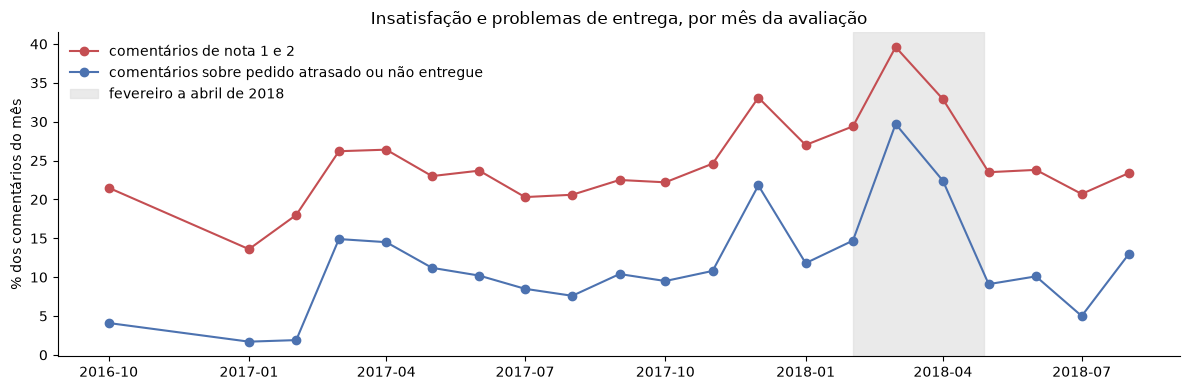

,negativos no pico,negativos fora do pico
faixa_atraso,,
dentro do prazo,47.0,64.7
atraso de 1 a 7 dias,17.4,9.0
atraso acima de 7 dias,24.6,10.0
não entregue,11.1,16.3


In [10]:
INICIO_PICO, FIM_PICO = "2018-02", "2018-04"

mensal = (
    tabela_base.assign(
        negativo=tabela_base["nota"] <= 2,
        problema_entrega=tabela_base["faixa_atraso"] != "dentro do prazo",
        despacho_atrasado=tabela_base["atraso_despacho_dias"] > 0,
    )
    .groupby("mes_avaliacao")
    .agg(
        comentarios=("review_id", "size"),
        pct_negativos=("negativo", "mean"),
        pct_problema_entrega=("problema_entrega", "mean"),
        pct_despacho_atrasado=("despacho_atrasado", "mean"),
        transporte_mediano_dias=("transporte_dias", "median"),
    )
)
for coluna in ["pct_negativos", "pct_problema_entrega", "pct_despacho_atrasado"]:
    mensal[coluna] = (mensal[coluna] * 100).round(1)
mensal = mensal[mensal["comentarios"] >= 100]
display(mensal)
print(f"correlação entre % de negativos e % com problema de entrega, mês a mês: "
      f"{mensal['pct_negativos'].corr(mensal['pct_problema_entrega']):.2f}")

fig, ax = plt.subplots(figsize=(12, 4))
x = pd.PeriodIndex(mensal.index, freq="M").to_timestamp()
ax.plot(x, mensal["pct_negativos"], marker="o", color="#C44E52", label="comentários de nota 1 e 2")
ax.plot(x, mensal["pct_problema_entrega"], marker="o", color="#4C72B0", label="comentários sobre pedido atrasado ou não entregue")
ax.axvspan(pd.Timestamp(f"{INICIO_PICO}-01"), pd.Timestamp(f"{FIM_PICO}-28"), color="#DDDDDD", alpha=0.6, label="fevereiro a abril de 2018")
ax.set(title="Insatisfação e problemas de entrega, por mês da avaliação", ylabel="% dos comentários do mês")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

negativos = tabela_base[tabela_base["nota"] <= 2]
no_pico = negativos["mes_avaliacao"].between(INICIO_PICO, FIM_PICO)
display(
    pd.DataFrame({
        "negativos no pico": negativos.loc[no_pico, "faixa_atraso"].value_counts(normalize=True),
        "negativos fora do pico": negativos.loc[~no_pico, "faixa_atraso"].value_counts(normalize=True),
    })
    .reindex(FAIXAS)
    .mul(100)
    .round(1)
)

**Leitura.** A previsão se confirmou. Mês a mês, a proporção de comentários negativos e a de comentários sobre pedidos atrasados ou não entregues têm correlação de 0,96. Em março de 2018, os problemas de entrega chegam a 29,7% dos comentários, contra cerca de 10% no restante do período, e os negativos a 39,6%. No mesmo período, o tempo mediano de transporte sobe de cerca de 7 dias para 9,9 em fevereiro e 12,1 em março, e o despacho atrasado pelo vendedor passa de cerca de 7% para 12%: os dois contribuem, e o transporte pesa mais.

Entre os comentários negativos, 53,0% se referem a pedidos com problema de entrega no pico, contra 35,3% fora dele. A diferença está no atraso, e não na falta de entrega: o atraso acima de 7 dias responde por 24,6% dos negativos no pico e por 10,0% fora dele, enquanto a parcela de não entregues é menor no pico (11,1% contra 16,3%).

O mesmo padrão aparece, em menor escala, em dezembro de 2017 (21,8% de comentários com problema de entrega). O pico de fevereiro a abril de 2018 tem origem logística e é um caso adequado para demonstrar o sistema.

📌 O pior mês, março de 2018, coincide com a greve dos Correios iniciada em 12 de março, de curta duração na maior parte do país. A coincidência não explica o pico sozinha: o tempo de transporte já subia em fevereiro, antes da greve. A greve dos caminhoneiros (21 a 30 de maio de 2018) não aparece nos dados: maio e junho ficam no patamar habitual.